<a href="https://colab.research.google.com/github/joansantoso/jax-ml/blob/main/DevFest26JKT_Finetune_Tunix_JAX_GPU_and_Serve_vLLM_FIX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚡ Notebook · Fine-tune Gemma 4 with **Tunix + JAX on a GPU**, serve it with vLLM as a reasoning agent
### 🇮🇩 Ava, NovaMart's Indonesian customer-service agent — the GPU / JAX variant of Notebook 2

By Joan Santoso (AI and Cloud AI GDE)

**Input:** the dataset from **Notebook 1** in Google Drive (`train.jsonl`, `test.jsonl`, `metadata.json`) — the same data Notebook 2 uses.
**Output:** a fine-tuned Gemma 4 that writes `<reasoning>…</reasoning>`, then a tool call or an answer, served by **vLLM on the GPU** behind an OpenAI-compatible API, driven by the same agent loop as Notebook 2.

| | Notebook 2 | **Notebook 3 (this one)** |
|---|---|---|
| Hardware | Colab TPU | **Colab GPU** (A100 or L4 recommended) |
| Framework | PyTorch on TorchTPU | **JAX + Flax NNX** |
| Fine-tuning library | transformers `Trainer` + PEFT LoRA | **[Tunix](https://github.com/google/tunix) `PeftTrainer` + [Qwix](https://github.com/google/qwix) LoRA** |
| QLoRA | not on TPU (no bitsandbytes backend) | **yes: Qwix NF4 (`USE_QLORA = True`)** — no bitsandbytes needed |
| Serving | vLLM TorchTPU | **vLLM (CUDA)** in its own virtual environment |

**Versions (pinned together):** `google-tunix 0.1.7` (has a native Gemma 4 model), `qwix 0.1.8`, `jax[cuda12] 0.11.1`, `flax 0.12.12`, `transformers 5.12.1`: the set this notebook was tested with on an L4. vLLM `0.32.0` lives in a separate virtual environment, because it pins its own PyTorch and CUDA libraries.

```
 Drive (Notebook 1)        Part A · JAX kernel                              Part B · after "Restart session"
 ┌──────────────┐   ┌────────────────────────────────────┐            ┌──────────────────────────────────┐
 │ train.jsonl  │──▶│ HF safetensors → Tunix Gemma4 (NNX)│──merge────▶│ vllm serve (venv, CUDA)          │
 │ test.jsonl   │   │ Qwix LoRA/QLoRA → Tunix PeftTrainer│  LoRA into │  ▲ agent: reason → tool →        │
 │ metadata.json│   │ Tunix Sampler: before / after      │  HF shards │    TOOL_RESULT → reason → answer │
 └──────────────┘   └────────────────────────────────────┘            └──────────────────────────────────┘
```

### Before you start
1. Run **Notebook 1** once so the dataset exists in Drive.
2. **Runtime ▸ Change runtime type ▸ GPU** — **A100** (40/80 GB) or **L4** (24 GB). A **T4** (16 GB) has no native bfloat16 and little memory: use `USE_QLORA = True`, `BATCH_SIZE = 1`, `GRAD_ACCUM = 8`, and expect vLLM to serve in float16.
3. Accept the Gemma license on Hugging Face, add a token to Colab **🔑 Secrets** as `HF_TOKEN`, and verify `MODEL_ID` in A1.

> **Why the LoRA adapters sit on the MLP layers.** vLLM needs a plain Hugging Face checkpoint, so the adapters are merged back into the original safetensors. Tunix 0.1.7 ships a merged-LoRA exporter for Gemma 3 but not yet for Gemma 4, whose attention weights are re-laid-out when loaded. The MLP projections (`gate_proj`, `up_proj`, `down_proj`) map 1:1 to Hugging Face weights (a plain transpose, taken from Tunix's own Gemma 4 loader), so this notebook targets them and merges them exactly.

# Part A — Fine-tuning with Tunix on the GPU
## A0. Install, then restart the session
Two separate environments, installed once:
1. **Training (this kernel):** JAX with CUDA 12, Flax, Qwix, Tunix and the Hugging Face tokenizer — pinned to versions released alongside Tunix 0.1.7.
2. **Serving (`/content/vllm-env`):** vLLM 0.32.0 in its own virtual environment, built with `uv`. vLLM pins `torch==2.13.0` and its own CUDA libraries, which would otherwise fight JAX's.

Everything installs with the kernel's own interpreter (`sys.executable -m pip`). Installation takes several minutes.

In [ ]:
import sys, subprocess, os

print("Python:", sys.version.split()[0])
!nvidia-smi --query-gpu=name,memory.total,compute_cap,driver_version --format=csv

PIP = [sys.executable, "-m", "pip"]
def run(cmd, label):
    r = subprocess.run(cmd, text=True, capture_output=True)
    print(("✅ " if r.returncode == 0 else "❌ ") + label)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-3000:])
    return r.returncode == 0

run(PIP + ["install", "-q", "--upgrade", "pip", "uv"], "pip + uv")

# 1) Training stack (this kernel), pinned to the versions this notebook was tested with
ok_train = run(PIP + ["install", "-q",
    "jax[cuda12]==0.11.1", "flax==0.12.12", "qwix==0.1.8", "google-tunix[prod]==0.1.7",
    "optax", "transformers==5.12.1", "huggingface_hub", "safetensors",
    "matplotlib", "openai", "gradio"], "training stack: JAX · Flax · Qwix · Tunix")

# 2) Serving stack in its own virtual environment (using --clear to overwrite existing venv)
VENV = "/content/vllm-env"
ok_venv = run([sys.executable, "-m", "uv", "venv", "--clear", "--python", sys.executable, VENV], "virtual environment for vLLM")
ok_serve = ok_venv and run([sys.executable, "-m", "uv", "pip", "install", "--python", f"{VENV}/bin/python",
                            "vllm==0.32.0"], "vLLM 0.32.0 (in /content/vllm-env)")

print("\nNow: Runtime ▸ Restart session, then continue with the next cell (skip this one).")

Python: 3.13.16
name, memory.total [MiB], compute_cap, driver_version
NVIDIA A100-SXM4-80GB, 81920 MiB, 8.0, 580.82.07
✅ pip + uv
✅ training stack: JAX · Flax · Qwix · Tunix
✅ virtual environment for vLLM
✅ vLLM 0.32.0 (in /content/vllm-env)

Now: Runtime ▸ Restart session, then continue with the next cell (skip this one).


### Meet JAX on the GPU
JAX compiles every function it runs through **XLA**, the same compiler TPUs use. On a GPU that means the first training step is slow (compilation) and the following ones are fast, and — just like on a TPU — **fixed shapes** keep it that way: every batch here is `[BATCH_SIZE, MAX_LEN]`.

By default JAX reserves 75% of the GPU's memory up front. Here we turn that reservation off (`XLA_PYTHON_CLIENT_PREALLOCATE=false`) and cap JAX at 80% (`XLA_PYTHON_CLIENT_MEM_FRACTION=0.80`). JAX keeps whatever it allocated until the process exits, which is why Part B starts with a session restart: vLLM can only take the GPU after this process lets go of it.

We also switch Weights & Biases off (`WANDB_MODE=disabled`). Tunix's metrics logger otherwise stops at an interactive W&B prompt in the middle of A5.

In [ ]:
import os
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.70"          # Lowered from 0.80 to give profiling/compilation more GPU memory headroom
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["WANDB_MODE"] = "disabled"          # no interactive W&B prompt from Tunix's metrics logger

import importlib.metadata as md_
import jax, jax.numpy as jnp
print("jax", jax.__version__, "| flax", md_.version("flax"), "| qwix", md_.version("qwix"),
      "| tunix", md_.version("google-tunix"), "| transformers", md_.version("transformers"))

gpus = [d for d in jax.devices() if d.platform == "gpu"]
assert gpus, "JAX sees no GPU: pick a GPU runtime and re-run A0 (and restart the session)"
for d in gpus:
    stats = d.memory_stats() or {}
    print(f"{d} · {d.device_kind} · {stats.get('bytes_limit', 0) / 2**30:.1f} GiB usable by JAX")

import subprocess
CC = float(subprocess.run(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"],
                          text=True, capture_output=True).stdout.split()[0])
BF16_NATIVE = CC >= 8.0
print(f"Compute capability {CC} -> native bfloat16: {BF16_NATIVE}" + ("" if BF16_NATIVE else "  (T4-class GPU: slower bf16, vLLM will use float16)"))

x = jnp.ones((2048, 2048), jnp.bfloat16)
print("matmul checksum:", float((x @ x).astype(jnp.float32).mean()))

from google.colab import userdata
from huggingface_hub import login
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
login(token=os.environ["HF_TOKEN"])

jax 0.11.1 | flax 0.12.12 | qwix 0.1.8 | tunix 0.1.7 | transformers 5.12.1


ERROR:jax._src.xla_bridge:Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 495, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 373, in initialize
    c_api = xb.register_plugin(
        'cuda', priority=500, library_path=str(path), options=options
    )
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 637, in register_plugin
    c_api = xla_client.load_pjrt_plugin_dynamically(plugin_name, library_path)
  File "/usr/local/lib/python3.13/dist-packages/jaxlib/xla_client.py", line 115, in load_pjrt_plugin_dynamically
    return _xla.load_pjrt_plugin(plugin_name, library_path, c_api=None)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
jax.errors.JaxRuntimeEr

cuda:0 · NVIDIA A100-SXM4-80GB · 55.5 GiB usable by JAX
Compute capability 8.0 -> native bfloat16: True
matmul checksum: 2048.0


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## A1. Configuration
`TUNIX_CONFIG` names Tunix's architecture config for the checkpoint: `gemma4_e2b` for `gemma-4-E2B-it`, `gemma4_e4b` for `gemma-4-E4B-it`. (Tunix's automatic lookup would ask for a `gemma4_e2b_it` config that doesn't exist, so we name it explicitly.)

Memory guide: A100 → defaults; L4 → defaults, or `USE_QLORA = True` for headroom; T4 → `USE_QLORA = True`, `BATCH_SIZE = 1`, `GRAD_ACCUM = 8`.

In [ ]:
MODEL_ID        = "google/gemma-4-E2B-it"   # ⚠️ verify the exact Gemma 4 repo id on Hugging Face
TUNIX_CONFIG    = "gemma4_e2b"              # Tunix ModelConfig for that checkpoint (gemma4_e4b for E4B)
DATA_DIR        = "/content/drive/MyDrive/gemma4-support-agent/data"   # written by Notebook 1
REASONING       = True     # train Ava to write <reasoning>…</reasoning> before every reply / tool call

MAX_LEN         = 768      # fixed sequence length: one shape = one compiled XLA program
BATCH_SIZE      = 1        # Reduced to 1 to prevent GPU OOM
GRAD_ACCUM      = 8        # Increased to 8 to maintain an effective batch size of 8
LR              = 2e-4
EPOCHS          = 1
MAX_OPT_STEPS   = 60     # e.g. 60 for a quick live demo
EVAL_EVERY      = 100      # optimizer steps between evaluations (the trainer also runs one before training)

LORA_RANK, LORA_ALPHA = 16, 32.0
LORA_TARGETS    = ".*gate_proj|.*up_proj|.*down_proj"   # MLP projections: exactly mergeable for vLLM (see the intro)
USE_QLORA       = True     # Enabled QLoRA to dramatically reduce memory footprint
QLORA_TILE_SIZE = 128      # NF4 block size; must divide the smallest weight dimension

WORK_DIR        = "/content/support-agent-jax"
MERGED_DIR      = f"{WORK_DIR}/merged"       # the Hugging Face checkpoint vLLM will serve
SAVE_TO_DRIVE   = False    # True = also copy the merged model to Drive
DRIVE_DIR       = "/content/drive/MyDrive/gemma4-support-agent/merged-jax"

os.makedirs(WORK_DIR, exist_ok=True)

## A2. Load the dataset from Drive
Reads Notebook 1's files, checks them against `metadata.json`, and expands every conversation into **one example per assistant turn** (history → that turn).

**How reasoning is trained.** With `REASONING = True`, each target is
```
<reasoning>Pelanggan ingin retur … Buka refund dengan start_refund …</reasoning>
<tool_call>{"name": "start_refund", "arguments": {…}}</tool_call>
```
Earlier assistant turns in the history keep only their content — reasoning is **not fed back** into later turns. The agent loop in Part B does exactly the same, so training and serving see identical conversations. The system prompt gets one extra instruction from `metadata.json` telling Ava to reason first.

In [ ]:
import json, re, os
from collections import Counter

if DATA_DIR.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

missing = [f for f in ("metadata.json", "train.jsonl", "test.jsonl") if not os.path.exists(f"{DATA_DIR}/{f}")]
assert not missing, f"Missing {missing} in {DATA_DIR}: run Notebook 1 first, or fix DATA_DIR in A1"

meta = json.load(open(f"{DATA_DIR}/metadata.json", encoding="utf-8"))
def read_jsonl(path): return [json.loads(l) for l in open(path, encoding="utf-8") if l.strip()]
train_convs, test_convs = read_jsonl(f"{DATA_DIR}/train.jsonl"), read_jsonl(f"{DATA_DIR}/test.jsonl")
assert len(train_convs) == meta["counts"]["train_conversations"] and len(test_convs) == meta["counts"]["test_conversations"], \
    "File sizes don't match metadata.json: re-run Notebook 1"
print(f"Dataset {meta['dataset']} v{meta['version']} ({meta['language']}), created {meta['created_at']}, seed {meta['seed']}")
print(f"{len(train_convs)} train / {len(test_convs)} test conversations")

# The prompt the model is trained with — and served with in Part B
REASON_OPEN, REASON_CLOSE = f"<{meta['reasoning_tag']}>", f"</{meta['reasoning_tag']}>"
SYSTEM_PROMPT = meta["system_prompt"] + ("\n\n" + meta["reasoning_instruction"] if REASONING else "")

def explode(convs):
    """One training example per assistant turn: the history so far -> that assistant turn."""
    return [{"id": c["id"], "intent": c["intent"], "messages": c["messages"][:i + 1]}
            for c in convs for i, m in enumerate(c["messages"]) if m["role"] == "assistant"]

def render_target(m):
    """The text Ava learns to produce: reasoning first (if enabled), then the reply or tool call."""
    return f"{REASON_OPEN}{m['reasoning']}{REASON_CLOSE}\n{m['content']}" if REASONING else m["content"]

def to_chat(ex):
    """Chat messages for the template. Earlier assistant turns keep only their content (reasoning is not fed back),
    exactly like the agent loop in Part B; only the final turn — the target — carries reasoning."""
    *history, target = ex["messages"]
    return [{"role": m["role"], "content": m["content"]} for m in history] + \
           [{"role": "assistant", "content": render_target(target)}]

train_examples, test_examples = explode(train_convs), explode(test_convs)
print(f"-> {len(train_examples)} train / {len(test_examples)} test examples (one per assistant turn) | reasoning: {REASONING}")
print("Intents (train):", dict(Counter(e["intent"] for e in train_examples)))

print("\n----- one training target -----")
print(to_chat(train_examples[5])[-1]["content"])

Mounted at /content/drive
Dataset novamart-cs-id v2.0 (id), created 2026-10-31T09:27:07+00:00, seed 7
1350 train / 150 test conversations
-> 3066 train / 341 test examples (one per assistant turn) | reasoning: True
Intents (train): {'refund': 503, 'out_of_scope': 137, 'order_status': 644, 'escalate': 312, 'password': 380, 'faq': 199, 'order_no_id': 384, 'damaged': 452, 'smalltalk': 55}

----- one training target -----
<reasoning>Ada nomor pesanan NM-222783. Status harus dicek lewat lookup_order sebelum saya menjawab.</reasoning>
<tool_call>{"name": "lookup_order", "arguments": {"order_id": "NM-222783"}}</tool_call>


## A3. Tokenize: reasoning targets, loss mask, static shapes
Same recipe as Notebook 2, in Tunix's format. Each example becomes two arrays of length `MAX_LEN`:
* `input_tokens` — the chat-templated conversation, right-padded with the pad token;
* `input_mask` — **1 only on the tokens Ava must learn** (reasoning + action + end-of-turn), 0 on the prompt and padding. Tunix's loss shifts it by one and uses it as the target mask, exactly like `labels = -100` in PyTorch.

In [ ]:
import numpy as np
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODEL_ID)
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else 0
print("pad id:", PAD_ID, "| bos id:", tok.bos_token_id)

def template_supports_system():
    try:
        out = tok.apply_chat_template([{"role": "system", "content": "SYS_TEST"}, {"role": "user", "content": "hi"}], tokenize=False)
        return "SYS_TEST" in out
    except Exception:
        return False

SUPPORTS_SYSTEM = template_supports_system()
print("Chat template supports a system role:", SUPPORTS_SYSTEM)

def with_system(msgs):
    if SUPPORTS_SYSTEM:
        return [{"role": "system", "content": SYSTEM_PROMPT}] + msgs
    first = dict(msgs[0]); first["content"] = SYSTEM_PROMPT + "\n\n" + first["content"]
    return [first] + msgs[1:]

def ids_of(text):
    ids = tok(text, add_special_tokens=False)["input_ids"]
    if tok.bos_token_id is not None and (not ids or ids[0] != tok.bos_token_id):
        ids = [tok.bos_token_id] + ids
    return ids

def encode(ex):
    """Returns (input_tokens, input_mask), or a reason tuple when the example can't be used."""
    msgs = with_system(to_chat(ex))          # reasoning on the target turn only (A2)
    prompt = tok.apply_chat_template(msgs[:-1], tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(msgs, tokenize=False)
    if not full.startswith(prompt):
        return "template_mismatch", full, prompt
    p_ids, f_ids = ids_of(prompt), ids_of(full)
    if len(f_ids) > MAX_LEN:
        return "too_long", len(f_ids)
    if PAD_ID in f_ids:
        return "pad_in_text", len(f_ids)       # positions/attention are derived from tokens != PAD_ID
    pad = MAX_LEN - len(f_ids)
    mask = [0] * len(p_ids) + [1] * (len(f_ids) - len(p_ids)) + [0] * pad
    return f_ids + [PAD_ID] * pad, mask

def build(examples, name):
    rows, too_long, mismatch, pad_in_text = [], [], [], 0
    for ex in examples:
        r = encode(ex)
        if r[0] == "too_long":
            too_long.append(r[1])
        elif r[0] == "template_mismatch":
            mismatch.append(r)
        elif r[0] == "pad_in_text":
            pad_in_text += 1
        else:
            rows.append(r)
    lengths = sorted([sum(1 for t in r[0] if t != PAD_ID) for r in rows] + too_long)
    stats = f"tokens median {lengths[len(lengths) // 2]}, max {lengths[-1]}" if lengths else "no lengths (every example mismatched)"
    print(f"{name}: kept {len(rows)}/{len(examples)} | too long: {len(too_long)} | template mismatch: {len(mismatch)} | "
          f"pad token in text: {pad_in_text} | {stats} (MAX_LEN = {MAX_LEN})")
    if too_long:
        print(f"  → longest example needs {max(too_long)} tokens: set MAX_LEN to at least that (a multiple of 128) in A1 and re-run A1–A3")
    if mismatch:
        _, full, prompt = mismatch[0]
        i = next((k for k, (a, b) in enumerate(zip(full, prompt)) if a != b), min(len(full), len(prompt)))
        print(f"  → the chat template renders the prompt differently from the full conversation; first difference at char {i}:")
        print(f"     prompt: {prompt[max(0, i - 60):i + 60]!r}\n     full:   {full[max(0, i - 60):i + 60]!r}")
    if len(rows) < 0.98 * len(examples):
        raise RuntimeError(f"{name}: {len(examples) - len(rows)} of {len(examples)} examples unusable — see the reasons above.")
    return {"input_tokens": np.array([r[0] for r in rows], dtype=np.int32),
            "input_mask":   np.array([r[1] for r in rows], dtype=bool)}

train_np, test_np = build(train_examples, "train"), build(test_examples, "test")
print("train arrays:", {k: v.shape for k, v in train_np.items()})

# Inspect what the model is trained on
ids, mask = train_np["input_tokens"][3], train_np["input_mask"][3]
print("\n----- full input -----\n" + tok.decode(ids[ids != PAD_ID]))
print("----- trained part (input_mask = 1) -----\n" + tok.decode(ids[mask]))

config.json:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

pad id: 0 | bos id: 2
Chat template supports a system role: True
train: kept 3066/3066 | too long: 0 | template mismatch: 0 | pad token in text: 0 | tokens median 457, max 636 (MAX_LEN = 768)
test: kept 341/341 | too long: 0 | template mismatch: 0 | pad token in text: 0 | tokens median 457, max 634 (MAX_LEN = 768)
train arrays: {'input_tokens': (3066, 768), 'input_mask': (3066, 768)}

----- full input -----
<bos><|turn>system
Kamu adalah Ava, agen layanan pelanggan NovaMart, toko online elektronik dan perlengkapan rumah.
Bersikaplah ramah, singkat, dan akurat. Jangan pernah mengarang detail pesanan: gunakan tool.

Tool:
- lookup_order(order_id): cek status pesanan
- start_refund(order_id, reason): buka pengembalian/refund. reason salah satu dari: defective, wrong_item, changed_mind, damaged
- reset_password(email): kirim tautan reset kata sandi
- escalate(summary): alihkan percakapan ke agen manusia

Untuk memanggil tool, balas HANYA dengan: <tool_call>{"name": "...", "arguments": {...

## A4. Load Gemma 4 into Tunix and attach LoRA with Qwix
1. **Mesh.** JAX describes how arrays are spread over devices with a *mesh*. With one GPU it's a 1×1 mesh; the axis names (`fsdp`, `tp`) are the ones Tunix's trainer shards data over, so the same code scales to several GPUs.
2. **Weights.** The Hugging Face safetensors are downloaded and converted into Tunix's Flax NNX `Gemma4` model by Tunix's own Gemma 4 loader (text decoder only; vision and audio towers are not loaded).
3. **LoRA / QLoRA.** `qwix.LoraProvider` adds rank-`LORA_RANK` adapters to every module whose path matches `LORA_TARGETS`. With `USE_QLORA = True` it also stores the frozen base weights of those modules in **NF4** (4-bit), which is QLoRA. Qwix traces one dummy forward pass to find the modules, using the model's own `get_model_input()`.

In [ ]:
import time
from flax import nnx
import qwix
from huggingface_hub import snapshot_download
from tunix.models.gemma4 import model as gemma4_lib
from tunix.models.gemma4 import params_safetensors as gemma4_st

NUM_DEVICES = jax.local_device_count()
mesh = jax.make_mesh((NUM_DEVICES, 1), ("fsdp", "tp"), axis_types=(jax.sharding.AxisType.Auto,) * 2)
print(f"Devices: {NUM_DEVICES} | mesh: {dict(mesh.shape)}")

BASE_DIR = snapshot_download(MODEL_ID, local_dir=f"/content/hf/{MODEL_ID.split('/')[-1]}", token=os.environ["HF_TOKEN"])
print("Checkpoint:", BASE_DIR)

model_cfg = getattr(gemma4_lib.ModelConfig, TUNIX_CONFIG)()
t = time.time()
with mesh:
    base_model = gemma4_st.create_model_from_safe_tensors(BASE_DIR, model_cfg, mesh=mesh, dtype=jnp.bfloat16)
print(f"Loaded Tunix Gemma4 ({model_cfg.num_layers} layers) in {time.time() - t:.0f}s")

lora_kwargs = dict(module_path=LORA_TARGETS, rank=LORA_RANK, alpha=LORA_ALPHA)
if USE_QLORA:
    lora_kwargs.update(weight_qtype="nf4", tile_size=QLORA_TILE_SIZE)
lora_model = qwix.apply_lora_to_model(base_model, qwix.LoraProvider(**lora_kwargs),
                                      rngs=nnx.Rngs(params=0), **base_model.get_model_input())
with jax.set_mesh(mesh):
    state = nnx.state(lora_model)
    nnx.update(lora_model, jax.lax.with_sharding_constraint(state, nnx.get_partition_spec(state)))

n_lora = sum(x.size for x in jax.tree.leaves(nnx.state(lora_model, nnx.LoRAParam)))
lora_modules = sorted({".".join(map(str, p[:-1])) for p, v in nnx.iter_graph(lora_model) if isinstance(v, nnx.LoRAParam)})
print(f"{'QLoRA (NF4)' if USE_QLORA else 'LoRA'}: {len(lora_modules)} adapted modules, {n_lora / 1e6:.2f} M trainable parameters")
print("e.g.", lora_modules[:3])

Devices: 1 | mesh: {'fsdp': 1, 'tp': 1}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Checkpoint: /content/hf/gemma-4-E2B-it


/tmp/ipykernel_1607/3215464496.py:17: DeprecationWarning: `with mesh:` context manager has been deprecated. Please use `with jax.set_mesh(mesh):` instead.
  with mesh:


Loaded Tunix Gemma4 (35 layers) in 9s
QLoRA (NF4): 105 adapted modules, 18.80 M trainable parameters
e.g. ['layers.0.mlp.down_proj', 'layers.0.mlp.gate_proj', 'layers.0.mlp.up_proj']


## A5. Train with Tunix's `PeftTrainer`
* **Batches** are plain dicts of NumPy arrays (`input_tokens`, `input_mask`), shuffled each epoch, last partial batch dropped → one shape for every step.
* **`gen_model_input`** turns a batch into what Gemma 4 expects: `positions` and a causal `attention_mask` that also hides padding (both built with Tunix's helpers from `tokens != PAD_ID`).
* **Optimizer:** Optax AdamW with gradient clipping; `gradient_accumulation_steps` makes the effective batch `BATCH_SIZE × GRAD_ACCUM`.
* The trainer **evaluates once before training** (the baseline: LoRA starts as a no-op, so this is the base model) and then every `EVAL_EVERY` steps. The first step includes XLA compilation.

For before/after answers we use **Tunix's `Sampler`** (KV-cached, greedy) directly on the JAX model. The cell below sets everything up and records the base model's answers; the training itself runs in the cell after it.

In [ ]:
import optax
from tunix.sft import peft_trainer, metrics_logger
from tunix.sft import utils as sft_utils
from tunix.sft import hooks as sft_hooks
from tunix.generate import sampler as sampler_lib
from transformers import GenerationConfig

GLOBAL_BS = BATCH_SIZE * NUM_DEVICES

def batches(data, bs, shuffle=False, seed=0):
    idx = np.arange(len(data["input_tokens"]))
    if shuffle:
        np.random.default_rng(seed).shuffle(idx)
    for i in range(0, len(idx) - bs + 1, bs):          # drop the last partial batch: fixed shapes
        j = idx[i:i + bs]
        yield {"input_tokens": data["input_tokens"][j], "input_mask": data["input_mask"][j]}

def train_stream():
    n, limit = 0, (MAX_OPT_STEPS * GRAD_ACCUM if MAX_OPT_STEPS else None)
    for epoch in range(EPOCHS):
        for b in batches(train_np, GLOBAL_BS, shuffle=True, seed=epoch):
            if limit is not None and n >= limit:
                return
            n += 1
            yield b

class EvalSet:                                           # re-iterable: the trainer evaluates several times
    def __iter__(self):
        return batches(test_np, GLOBAL_BS)

NUM_EVAL_BATCHES = len(test_np["input_tokens"]) // GLOBAL_BS
TOTAL_OPT_STEPS = (MAX_OPT_STEPS or EPOCHS * (len(train_np["input_tokens"]) // GLOBAL_BS) // GRAD_ACCUM)

def gen_model_input(x):
    pad_mask = x["input_tokens"] != PAD_ID
    return {"input_tokens": x["input_tokens"], "input_mask": x["input_mask"],
            "positions": sft_utils.build_positions_from_mask(pad_mask),
            "attention_mask": sft_utils.make_causal_attn_mask(pad_mask)}

class Progress(sft_hooks.TrainingHooks):
    """Tunix training hooks: print progress and keep the curves for plotting."""
    def __init__(self):
        self.train_log, self.eval_log, self.t0, self._in_eval = [], [], None, False
    def on_train_start(self, _):
        self.t0 = time.time(); print(f"Training {TOTAL_OPT_STEPS} optimizer steps (first step includes XLA compilation)…")
    def on_train_end(self, _):
        print(f"✅ Done in {(time.time() - self.t0) / 60:.1f} min")
    def on_train_step_start(self, _):
        self._in_eval = False
    def on_train_step_end(self, _, step, loss):
        loss = float(loss); self.train_log.append((step, loss))
        if step <= 2 or step % 10 == 0:
            print(f"step {step:4d}/{TOTAL_OPT_STEPS} | loss {loss:.4f} | {time.time() - self.t0:6.0f}s")
    def on_eval_step_start(self, _):
        self._in_eval = True
    def on_eval_step_end(self, _, eval_loss):
        avg = float(eval_loss) / max(1, NUM_EVAL_BATCHES)
        step = self.train_log[-1][0] if self.train_log else 0
        self.eval_log.append((step, avg))
        print(f"eval @ step {step}: loss {avg:.4f}" + ("  (baseline = base model)" if step == 0 else ""))

optimizer = optax.chain(optax.clip_by_global_norm(1.0), optax.adamw(LR, weight_decay=0.0))
trainer = peft_trainer.PeftTrainer(
    lora_model, optimizer,
    peft_trainer.TrainingConfig(
        eval_every_n_steps=EVAL_EVERY,
        gradient_accumulation_steps=GRAD_ACCUM if GRAD_ACCUM > 1 else None,
        metrics_logging_options=metrics_logger.MetricsLoggerOptions(log_dir=f"{WORK_DIR}/logs"),
    ),
).with_gen_model_input_fn(gen_model_input)
progress = Progress()
trainer.with_training_hooks(progress)        # sets the hooks in place (returns None)

# ---- before/after answers with Tunix's KV-cached Sampler ----
gen_cfg = GenerationConfig.from_pretrained(BASE_DIR)
eos = gen_cfg.eos_token_id if isinstance(gen_cfg.eos_token_id, list) else [gen_cfg.eos_token_id]
EOS_IDS = sorted({i for i in eos + [tok.eos_token_id] if i is not None})

def sample_reply(msgs, max_new_tokens=192):
    prompt = tok.apply_chat_template(with_system(msgs), tokenize=False, add_generation_prompt=True)
    n = len(tok.encode(prompt)) + 1                       # +1: the sampler may add a BOS token
    prompt_len = MAX_LEN if n <= MAX_LEN else 1 << (n - 1).bit_length()   # the sampler pads longer prompts to a power of 2
    sampler = sampler_lib.Sampler(lora_model, tok, sampler_lib.CacheConfig(   # built fresh: picks up current weights
        cache_size=prompt_len + max_new_tokens, num_layers=model_cfg.num_layers,
        num_kv_heads=model_cfg.num_kv_heads, head_dim=model_cfg.head_dim))
    with mesh:
        out = sampler([prompt], max_generation_steps=max_new_tokens, max_prompt_length=prompt_len, eos_tokens=EOS_IDS)
    return out.text[0].strip()

DEMO_PROMPTS = [[{"role": "user", "content": "Halo kak, pesanan NM-482913 saya sudah sampai mana?"}],
                [{"role": "user", "content": "Kasih resep rendang dong."}]]
before = [sample_reply(p) for p in DEMO_PROMPTS]
for p, r in zip(DEMO_PROMPTS, before):
    print(f"👤 {p[-1]['content']}\n🤖 (base) {r}\n")

wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
/tmp/ipykernel_1607/3310144322.py:86: DeprecationWarning: `with mesh:` context manager has been deprecated. Please use `with jax.set_mesh(mesh):` instead.
  with mesh:


👤 Halo kak, pesanan NM-482913 saya sudah sampai mana?
🤖 (base) <reasoning>Pelanggan menanyakan status pesanan dengan ID NM-482913. Saya perlu menggunakan tool lookup_order untuk memeriksa status pesanan tersebut.</reasoning>
<tool_call>{"name": "lookup_order", "arguments": {"order_id": "NM-482913"}}</tool_call>

👤 Kasih resep rendang dong.
🤖 (base) <reasoning>Pelanggan meminta resep masakan, yang tidak relevan dengan layanan pelanggan NovaMart (toko elektronik dan perlengkapan rumah).</reasoning>
Maaf, saya adalah agen layanan pelanggan NovaMart dan hanya bisa membantu dengan pertanyaan terkait pesanan, produk, atau layanan kami. Saya tidak bisa memberikan resep masakan.

<tool_call>
</tool_call>



### Run the training
One epoch over the 3,066 training examples with the defaults in A1 is `3066 // (BATCH_SIZE × GRAD_ACCUM)` = **383 optimizer steps**. For a live demo, set `MAX_OPT_STEPS = 60` in A1 and re-run A1 and A5 first.

The trainer evaluates the base model before the first step, then every `EVAL_EVERY` steps, so the eval curve starts at the baseline.

In [ ]:
with jax.set_mesh(mesh):
    trainer.train(train_stream(), EvalSet())

assert progress.train_log, "No training steps ran: check the dataset arrays from A3 and MAX_OPT_STEPS in A1"
print(f"Last training loss: {progress.train_log[-1][1]:.4f} after {progress.train_log[-1][0]} steps")
if len(progress.eval_log) >= 2:
    base, final = progress.eval_log[0][1], progress.eval_log[-1][1]
    print(f"Eval loss: {base:.4f} (base model) -> {final:.4f} (fine-tuned), {100 * (base - final) / base:.0f}% lower")


eval @ step 0: loss 3.2171  (baseline = base model)
Training 60 optimizer steps (first step includes XLA compilation)…
step    1/60 | loss 3.6688 |    144s
step    2/60 | loss 1.7087 |    145s
step   10/60 | loss 0.7168 |    154s
step   20/60 | loss 0.2941 |    164s
step   30/60 | loss 0.1178 |    175s
step   40/60 | loss 0.1431 |    186s
step   50/60 | loss 0.0407 |    196s
✅ Done in 3.4 min
step   60/60 | loss 0.0324 |    206s
Last training loss: 0.0324 after 60 steps


### Loss curves and before/after answers
The plot is saved to `WORK_DIR/loss_curves.png` so you can drop it into slides.

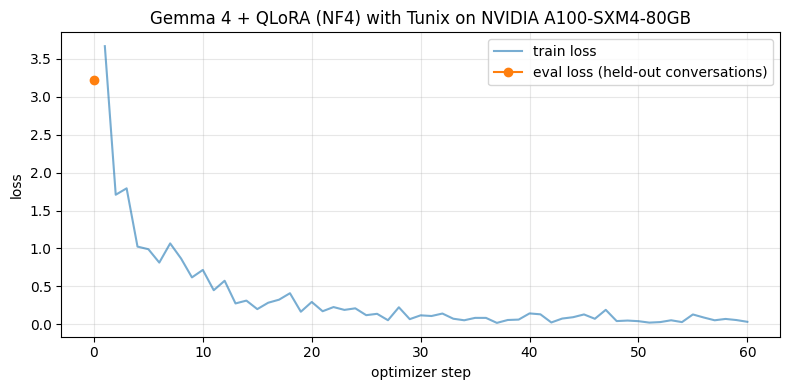

/tmp/ipykernel_1607/3310144322.py:86: DeprecationWarning: `with mesh:` context manager has been deprecated. Please use `with jax.set_mesh(mesh):` instead.
  with mesh:


👤 Halo kak, pesanan NM-482913 saya sudah sampai mana?
🤖 (base)       <reasoning>Pelanggan menanyakan status pesanan dengan ID NM-482913. Saya perlu menggunakan tool lookup_order untuk memeriksa status pesanan tersebut.</reasoning>
<tool_call>{"name": "lookup_order", "arguments": {"order_id": "NM-482913"}}</tool_call>
🤖 (fine-tuned) <reasoning>Pelanggan menanyakan pesanan NM-482913. Saya tidak boleh menebak statusnya, jadi saya cek dengan lookup_order.</reasoning>
<tool_call>{"name": "lookup_order", "arguments": {"order_id": "NM-482913"}}</tool_call>

👤 Kasih resep rendang dong.
🤖 (base)       <reasoning>Pelanggan meminta resep masakan, yang tidak relevan dengan layanan pelanggan NovaMart (toko elektronik dan perlengkapan rumah).</reasoning>
Maaf, saya adalah agen layanan pelanggan NovaMart dan hanya bisa membantu dengan pertanyaan terkait pesanan, produk, atau layanan kami. Saya tidak bisa memberikan resep masakan.

<tool_call>
</tool_call>
🤖 (fine-tuned) <reasoning>Permintaan ini di l

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(*zip(*progress.train_log), label="train loss", alpha=0.6)
if progress.eval_log:
    ax.plot(*zip(*progress.eval_log), "o-", label="eval loss (held-out conversations)")
ax.set_xlabel("optimizer step"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f"Gemma 4 + {'QLoRA (NF4)' if USE_QLORA else 'LoRA'} with Tunix on {jax.devices()[0].device_kind}")
fig.tight_layout(); fig.savefig(f"{WORK_DIR}/loss_curves.png", dpi=150); plt.show()

# Safely clear active JAX metric/monitoring callbacks to prevent background WandB calls
from jax._src import monitoring
monitoring._scalar_listeners.clear()

after = [sample_reply(p) for p in DEMO_PROMPTS]
for p, b, a in zip(DEMO_PROMPTS, before, after):
    print(f"👤 {p[-1]['content']}\n🤖 (base)       {b}\n🤖 (fine-tuned) {a}\n")

## A6. Merge LoRA into the Hugging Face checkpoint for vLLM
For every adapted module, the update is `ΔW = (A·B) · α/r` in Tunix's kernel layout `(in, out)`. Tunix's Gemma 4 loader shows that an MLP kernel is the Hugging Face weight **transposed**, so `ΔW_HF = ΔWᵀ`. We add it to the original **bfloat16** weights, shard by shard, keeping the file names and `model.safetensors.index.json` — so the output loads exactly like the original checkpoint. With QLoRA this still merges into the full-precision originals, not the 4-bit copies.

A final check re-reads one merged tensor and confirms that `merged − original` equals the LoRA update.

In [ ]:
import re, glob, json, shutil
from safetensors import safe_open
from safetensors.flax import load_file, save_file

cpu = jax.devices("cpu")[0]
MLP_RE = re.compile(r"layers\.(\d+)\.mlp\.(gate_proj|up_proj|down_proj)$")

# 1) collect LoRA pairs → ΔW in Hugging Face layout, on CPU
pairs = {}
for path, v in nnx.iter_graph(lora_model):
    if isinstance(v, nnx.LoRAParam):
        pairs.setdefault(".".join(map(str, path[:-1])), {})[str(path[-1])] = jax.device_put(jnp.asarray(getattr(v, "value", v)), cpu)

shards = sorted(glob.glob(f"{BASE_DIR}/*.safetensors"))
hf_keys = {k for s in shards for k in safe_open(s, framework="flax").keys()}

def hf_key(module_path):
    m = MLP_RE.search(module_path)
    if not m:
        raise ValueError(f"Export supports MLP LoRA targets only; got {module_path!r}. Keep LORA_TARGETS on gate/up/down_proj.")
    suffix = f"layers.{m.group(1)}.mlp.{m.group(2)}.weight"
    hits = [k for k in hf_keys if k.endswith(suffix) and not any(t in k for t in ("vision", "audio"))]
    assert len(hits) == 1, f"expected one Hugging Face key ending in {suffix}, found {hits}"
    return hits[0]

with jax.default_device(cpu):
    deltas = {}
    for mod, ab in pairs.items():
        # Qwix names the pair <param>_lora_a / <param>_lora_b, e.g. kernel_lora_a: a is (in, r), b is (r, out)
        a = next(v for n, v in ab.items() if n.endswith("lora_a")).astype(jnp.float32)
        b = next(v for n, v in ab.items() if n.endswith("lora_b")).astype(jnp.float32)
        deltas[hf_key(mod)] = ((a @ b) * (LORA_ALPHA / LORA_RANK)).T      # (in,out) kernel → (out,in) HF weight
print(f"{len(deltas)} LoRA updates mapped to Hugging Face weights")
delta_max = max(float(jnp.max(jnp.abs(d))) for d in deltas.values())
assert delta_max > 0, "Every LoRA update is zero: the adapters were never trained. Run the training cell in A5 first."
print(f"largest |ΔW| entry: {delta_max:.2e}")

# 2) write merged shards with the original names; copy everything else (config, tokenizer, index, chat template…)
if os.path.exists(MERGED_DIR):
    shutil.rmtree(MERGED_DIR)
os.makedirs(MERGED_DIR)
merged = 0
with jax.default_device(cpu):
    for s in shards:
        tensors = load_file(s)
        for k in tensors.keys() & deltas.keys():
            w = tensors[k]
            assert w.shape == deltas[k].shape, f"{k}: weight {w.shape} vs update {deltas[k].shape}"
            tensors[k] = (w.astype(jnp.float32) + deltas[k]).astype(w.dtype)
            merged += 1
        save_file(tensors, f"{MERGED_DIR}/{os.path.basename(s)}", metadata={"format": "pt"})
        del tensors
for f in os.listdir(BASE_DIR):
    src = os.path.join(BASE_DIR, f)
    if os.path.isfile(src) and not f.endswith(".safetensors"):
        shutil.copy(src, MERGED_DIR)
assert merged == len(deltas), f"merged {merged} of {len(deltas)} updates"
print(f"✅ merged {merged} weights into {len(shards)} shard(s) → {MERGED_DIR}")

# 3) verify one tensor: merged − original == ΔW
k = next(iter(deltas))
src_shard = next(s for s in shards if k in safe_open(s, framework="flax").keys())
with jax.default_device(cpu):
    orig = safe_open(src_shard, framework="flax").get_tensor(k).astype(jnp.float32)
    new = safe_open(f"{MERGED_DIR}/{os.path.basename(src_shard)}", framework="flax").get_tensor(k).astype(jnp.float32)
    err = float(jnp.max(jnp.abs((new - orig) - deltas[k]))); scale = float(jnp.max(jnp.abs(deltas[k])))
print(f"check {k}: max |(merged − original) − ΔW| = {err:.2e} (ΔW max {scale:.2e}; bf16 rounding only)")

# 4) serving config + held-out examples, as in Notebook 2
json.dump({"base_model": MODEL_ID, "language": "id", "framework": "tunix-jax-gpu",
           "is_multimodal": any(k in json.load(open(f"{BASE_DIR}/config.json")) for k in ("vision_config", "audio_config")),
           "system_prompt": SYSTEM_PROMPT, "supports_system_role": SUPPORTS_SYSTEM,
           "train_examples": int(len(train_np["input_tokens"])),
           "eval_loss_base": progress.eval_log[0][1] if progress.eval_log else None,
           "eval_loss_finetuned": progress.eval_log[-1][1] if progress.eval_log else None,
           "reasoning": REASONING, "reasoning_tag": meta["reasoning_tag"],
           "lora": {"rank": LORA_RANK, "alpha": LORA_ALPHA, "targets": LORA_TARGETS, "qlora": USE_QLORA},
           "dataset": {"name": meta["dataset"], "version": meta["version"], "created_at": meta["created_at"], "seed": meta["seed"]}},
          open(f"{MERGED_DIR}/workshop_config.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
with open(f"{MERGED_DIR}/test_examples.jsonl", "w", encoding="utf-8") as f:
    for e in test_examples:
        f.write(json.dumps(e, ensure_ascii=False) + "\n")
!ls -lh {MERGED_DIR}

/tmp/ipykernel_1607/4101462317.py:12: DeprecationWarning: '.value' access is now deprecated. For Variable[Array] instances use:

  variable[...]

For other Variable types use:

  variable.get_value()

  pairs.setdefault(".".join(map(str, path[:-1])), {})[str(path[-1])] = jax.device_put(jnp.asarray(getattr(v, "value", v)), cpu)


105 LoRA updates mapped to Hugging Face weights
largest |ΔW| entry: 8.49e-03
✅ merged 105 weights into 1 shard(s) → /content/support-agent-jax/merged
check model.language_model.layers.0.mlp.down_proj.weight: max |(merged − original) − ΔW| = 7.89e-04 (ΔW max 1.47e-03; bf16 rounding only)
total 9.6G
-rw-r--r-- 1 root root  19K Oct 31 14:59 chat_template.jinja
-rw-r--r-- 1 root root 4.9K Oct 31 14:59 config.json
-rw-r--r-- 1 root root  208 Oct 31 14:59 generation_config.json
-rw-r--r-- 1 root root 9.6G Oct 31 14:59 model.safetensors
-rw-r--r-- 1 root root 1.7K Oct 31 14:59 processor_config.json
-rw-r--r-- 1 root root  28K Oct 31 14:59 README.md
-rw-r--r-- 1 root root 247K Oct 31 14:59 test_examples.jsonl
-rw-r--r-- 1 root root 3.1K Oct 31 14:59 tokenizer_config.json
-rw-r--r-- 1 root root  31M Oct 31 14:59 tokenizer.json
-rw-r--r-- 1 root root 1.8K Oct 31 14:59 workshop_config.json


In [ ]:
SAVE_TO_DRIVE=True
if SAVE_TO_DRIVE:
    shutil.copytree(MERGED_DIR, DRIVE_DIR, dirs_exist_ok=True)
    print("✅ Copied to", DRIVE_DIR)
else:
    print(f"Merged model kept in {MERGED_DIR} (SAVE_TO_DRIVE = False). It survives a session restart, not a new runtime.")


✅ Copied to /content/drive/MyDrive/gemma4-support-agent/merged-jax


# Part B — Serve with vLLM on the GPU
### 🔄 Restart the session first
**Runtime ▸ Restart session**, then run only the cells below. JAX is still holding the GPU memory it used for training (up to 80%); a restart frees it. Installed packages, `/content/vllm-env` and the merged model in `/content` all survive the restart.

The server runs from the separate vLLM environment, on the merged checkpoint: on GPUs with native bfloat16 (A100, L4) in bfloat16, on a T4 in float16. If your vLLM build supports `--language-model-only`, it is added so Gemma 4's vision/audio encoders aren't loaded.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, json, subprocess, time, requests
os.environ.pop("VLLM_USE_V1", None)                # no longer exists in vLLM (see the "Unknown vLLM environment variable" warning)
os.environ["VLLM_USE_FLASHINFER_SAMPLER"] = "0"

In [ ]:
!/usr/bin/env python -m uv pip install --python /content/vllm-env/bin/python ninja
os.environ["PATH"] = "/content/vllm-env/bin:" + os.environ["PATH"]      # so FlashInfer finds the venv's ninja
if os.path.exists("/usr/local/cuda"):
    os.environ["CUDA_HOME"] = "/usr/local/cuda"                  # nvcc for the JIT build

Using Python 3.13.16 environment at: vllm-env
Checked 1 package in 2ms


In [ ]:
LOCAL_DIR = "/content/support-agent-jax/merged"                    # written by A6 in this runtime
DRIVE_DIR = "/content/drive/MyDrive/gemma4-support-agent/merged-jax"  # written by A6 when SAVE_TO_DRIVE = True
MODEL_DIR = DRIVE_DIR
VLLM = "/content/vllm-env/bin/vllm"
assert os.path.exists(VLLM), "vLLM venv missing: re-run A0"
cfg = json.load(open(f"{MODEL_DIR}/workshop_config.json", encoding="utf-8"))
print("Serving", MODEL_DIR, "| base:", cfg["base_model"], "| LoRA:", cfg["lora"])

cc = float(subprocess.run(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"], text=True, capture_output=True).stdout.split()[0])
dtype = "bfloat16" if cc >= 8.0 else "half"
cmd = [VLLM, "serve", MODEL_DIR, "--served-model-name", "support-agent", "--dtype", dtype,
       "--max-model-len", "2048", "--max-num-seqs", "32", "--gpu-memory-utilization", "0.70", "--port", "8000"]
help_text = subprocess.run([VLLM, "serve", "--help=all"], text=True, capture_output=True).stdout
if "--language-model-only" in help_text:
    cmd.append("--language-model-only")
print(" ".join(cmd))

log = open("/content/vllm.log", "w")
server = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT)
t0 = time.time()
while True:
    try:
        if requests.get("http://localhost:8000/health", timeout=2).status_code == 200:
            print(f"✅ vLLM is ready after {time.time() - t0:.0f}s"); break
    except requests.exceptions.RequestException:
        pass
    if server.poll() is not None:
        print("❌ vLLM exited — see the log below"); break
    if time.time() - t0 > 1200:
        print("⏰ Still not ready after 20 min — see the log below"); break
    time.sleep(10)
!tail -n 25 /content/vllm.log

Serving /content/drive/MyDrive/gemma4-support-agent/merged-jax | base: google/gemma-4-E2B-it | LoRA: {'rank': 16, 'alpha': 32.0, 'targets': '.*gate_proj|.*up_proj|.*down_proj', 'qlora': True}
/content/vllm-env/bin/vllm serve /content/drive/MyDrive/gemma4-support-agent/merged-jax --served-model-name support-agent --dtype bfloat16 --max-model-len 2048 --max-num-seqs 32 --gpu-memory-utilization 0.70 --port 8000 --language-model-only
✅ vLLM is ready after 70s
(APIServer pid=18630) INFO 10-31 15:15:18 [launcher.py:195] Route: /ping, Methods: POST
(APIServer pid=18630) INFO 10-31 15:15:18 [launcher.py:195] Route: /invocations, Methods: POST
(APIServer pid=18630) INFO 10-31 15:15:18 [launcher.py:195] Route: /v1/chat/completions, Methods: POST
(APIServer pid=18630) INFO 10-31 15:15:18 [launcher.py:195] Route: /v1/chat/completions/batch, Methods: POST
(APIServer pid=18630) INFO 10-31 15:15:18 [launcher.py:195] Route: /v1/responses, Methods: POST
(APIServer pid=18630) INFO 10-31 15:15:18 [launch

In [ ]:
import os
if os.path.exists('/content/vllm.log'):
    with open('/content/vllm.log', 'r') as f:
        print(f.read())
else:
    print('vllm.log not found!')

(APIServer pid=18630) INFO 10-31 15:14:26 [api_utils.py:347] 
(APIServer pid=18630) INFO 10-31 15:14:26 [api_utils.py:347]        █     █     █▄   ▄█
(APIServer pid=18630) INFO 10-31 15:14:26 [api_utils.py:347]  ▄▄ ▄█ █     █     █ ▀▄▀ █  version 0.32.0
(APIServer pid=18630) INFO 10-31 15:14:26 [api_utils.py:347]   █▄█▀ █     █     █     █  model   /content/drive/MyDrive/gemma4-support-agent/merged-jax
(APIServer pid=18630) INFO 10-31 15:14:26 [api_utils.py:347]    ▀▀  ▀▀▀▀▀ ▀▀▀▀▀ ▀     ▀
(APIServer pid=18630) INFO 10-31 15:14:26 [api_utils.py:347] 
(APIServer pid=18630) INFO 10-31 15:14:26 [api_utils.py:286] non-default args: {'model_tag': '/content/drive/MyDrive/gemma4-support-agent/merged-jax', 'model': '/content/drive/MyDrive/gemma4-support-agent/merged-jax', 'dtype': 'bfloat16', 'max_model_len': 2048, 'served_model_name': ['support-agent'], 'gpu_memory_utilization': 0.7, 'language_model_only': True, 'max_num_seqs': 32}
(APIServer pid=18630) INFO 10-31 15:14:26 [model.py:733] Resol

## B1. Talk to the model through the OpenAI-compatible API
`split_reasoning()` separates Ava's `<reasoning>` from what the customer sees. The reasoning is shown to *you* (💭) and never sent to the customer.

In [ ]:
import re
from openai import OpenAI
client = OpenAI(base_url="http://localhost:8000/v1", api_key="not-needed")
SYSTEM_PROMPT = cfg["system_prompt"]
TAG = cfg.get("reasoning_tag", "reasoning")
REASON_RE = re.compile(rf"<{TAG}>(.*?)</{TAG}>", re.S)

def with_system(msgs):
    if cfg["supports_system_role"]:
        return [{"role": "system", "content": SYSTEM_PROMPT}] + msgs
    first = dict(msgs[0]); first["content"] = SYSTEM_PROMPT + "\n\n" + first["content"]
    return [first] + msgs[1:]

def chat(msgs, temperature=0.2, max_tokens=400):
    r = client.chat.completions.create(model="support-agent", messages=with_system(msgs),
                                       temperature=temperature, max_tokens=max_tokens)
    return r.choices[0].message.content.strip()

def split_reasoning(text):
    """('reasoning', 'visible part'). Text without a reasoning block returns ('', text)."""
    m = REASON_RE.search(text)
    if not m:
        return "", text.strip()
    return m.group(1).strip(), (text[:m.start()] + text[m.end():]).strip()

for q in ["Halo, pesanan saya NM-482913 sudah sampai mana?", "Bagaimana kebijakan pengembalian barang?", "Buatkan puisi tentang kucing dong."]:
    reasoning, answer = split_reasoning(chat([{"role": "user", "content": q}]))
    print(f"👤 {q}\n   💭 {reasoning or '(no reasoning)'}\n🤖 {answer}\n")

👤 Halo, pesanan saya NM-482913 sudah sampai mana?
   💭 Pelanggan menanyakan pesanan NM-482913. Saya tidak boleh menebak statusnya, jadi saya cek dengan lookup_order.
🤖 <tool_call>{"name": "lookup_order", "arguments": {"order_id": "NM-482913"}}</tool_call>

👤 Bagaimana kebijakan pengembalian barang?
   💭 Ini pertanyaan umum tentang retur. Jawabannya ada di kebijakan toko, jadi tidak perlu tool.
🤖 Menurut kebijakan NovaMart, Kakak punya waktu maksimal 30 hari setelah barang diterima untuk retur. Barang harus dalam kondisi baik, dan dana dikembalikan ke metode pembayaran awal dalam 5-7 hari kerja.

👤 Buatkan puisi tentang kucing dong.
   💭 Permintaan pelanggan di luar layanan NovaMart. Tolak dengan sopan dan tawarkan bantuan yang berkaitan dengan toko.
🤖 Wah, itu di luar yang bisa saya bantu di sini, Kak. Saya asisten layanan pelanggan NovaMart, jadi saya bisa bantu soal pesanan, retur, pengiriman, atau akun Kakak. Ada yang mau saya cek?



## B2. The agent loop: reason → tool → `TOOL_RESULT` → reason → answer
`agent_turn()` sends the conversation to vLLM. When Ava replies with a `<tool_call>`, the loop runs the tool, adds the result as a `TOOL_RESULT:` message and asks again, until Ava answers in text (at most `max_steps` calls). Earlier assistant turns carry only their content, never their reasoning, exactly as in training (A2).

The tools here are a **mock NovaMart backend** that returns the same shapes as Notebook 1's tool results, deterministic per order id so a demo repeats. Swap `run_tool()` for your real APIs.

In [ ]:
import json, random, hashlib
from datetime import date, timedelta

TOOL_RE = re.compile(r"<tool_call>\s*(\{.*\})\s*</tool_call>", re.S)
EMPTY_CALL_RE = re.compile(r"<tool_call>\s*</tool_call>")
ORDER_RE = re.compile(r"^NM-\d{6}$")
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
PRODUCTS = ["earbud nirkabel", "monitor 4K", "air fryer", "keyboard mekanik", "robot penyedot debu", "jam tangan pintar",
            "mesin espresso", "mouse gaming", "meja berdiri", "speaker Bluetooth", "hub USB-C", "ketel listrik"]
CARRIERS = ["JNE", "J&T Express", "SiCepat", "AnterAja"]
REFUND_REASONS = {"defective", "wrong_item", "changed_mind", "damaged"}

def _rng(key): return random.Random(int(hashlib.md5(key.encode()).hexdigest()[:8], 16))
def _tgl(d): return f"{d.day} {BULAN[d.month - 1]}"

def run_tool(name, args):
    """Mock NovaMart backend. Same result shapes as Notebook 1's TOOL_RESULT messages."""
    today = date.today()
    if name in ("lookup_order", "start_refund"):
        oid = str(args.get("order_id", "")).strip().upper()
        if not ORDER_RE.match(oid):
            return {"error": "order_not_found", "order_id": oid}
    if name == "lookup_order":
        r = _rng(oid)
        res = {"order_id": oid, "item": r.choice(PRODUCTS), "status": r.choice(["processing", "shipped", "out_for_delivery", "delivered"])}
        if res["status"] == "processing":
            res["ships_by"] = _tgl(today + timedelta(days=r.randint(1, 4)))
        elif res["status"] == "shipped":
            res.update(carrier=r.choice(CARRIERS), tracking=f"RESI{r.randint(10**8, 10**9 - 1)}", eta=_tgl(today + timedelta(days=r.randint(1, 5))))
        elif res["status"] == "out_for_delivery":
            res["carrier"] = r.choice(CARRIERS)
        else:
            res["delivered_on"] = _tgl(today - timedelta(days=r.randint(0, 6)))
        return res
    if name == "start_refund":
        if args.get("reason") not in REFUND_REASONS:
            return {"error": "invalid_reason", "allowed": sorted(REFUND_REASONS)}
        r = _rng(oid + ":refund")
        if r.random() < 0.2:
            return {"error": "outside_return_window", "order_id": oid, "delivered_on": _tgl(today - timedelta(days=r.randint(40, 90)))}
        return {"refund_id": f"RF-{r.randint(10000, 99999)}", "order_id": oid, "status": "approved",
                "amount": r.randrange(150_000, 8_000_000, 1_000), "currency": "IDR", "return_label": "emailed"}
    if name == "reset_password":
        email = str(args.get("email", "")).strip()
        return {"status": "sent", "email": email} if "@" in email else {"error": "invalid_email", "email": email}
    if name == "escalate":
        r = _rng(str(args.get("summary", "")))
        return {"ticket_id": f"T-{r.randint(10000, 99999)}", "wait_minutes": r.randint(2, 20)}
    return {"error": "unknown_tool", "name": name}

def agent_turn(history, user_message, trace=None, max_steps=4):
    """One customer message in, Ava's final text answer out. Tool calls run in between.
    trace (optional list) collects reasoning strings and "🔧 tool(args) → result" lines."""
    msgs = list(history) + [{"role": "user", "content": user_message}]
    for _ in range(max_steps):
        reasoning, visible = split_reasoning(chat(msgs))
        if trace is not None and reasoning:
            trace.append(reasoning)
        m = TOOL_RE.search(visible)
        if not m:
            return EMPTY_CALL_RE.sub("", visible).strip()
        try:
            call = json.loads(m.group(1))
            name, args = call["name"], call.get("arguments", {})
            result = run_tool(name, args)
        except (json.JSONDecodeError, KeyError, TypeError) as e:
            name, args, result = "?", {}, {"error": f"invalid_tool_call: {e}"}
        if trace is not None:
            trace.append(f"🔧 {name}({json.dumps(args, ensure_ascii=False)}) → {json.dumps(result, ensure_ascii=False)}")
        msgs += [{"role": "assistant", "content": m.group(0)},
                 {"role": "user", "content": "TOOL_RESULT: " + json.dumps(result, ensure_ascii=False)}]
    return "Maaf, Kak, saya belum bisa menyelesaikan permintaan ini. Saya hubungkan ke agen manusia ya."

for q in ["Pesanan NM-555123 sudah sampai mana?",
          "Saya mau retur monitor 4K, pesanan NM-777001, tidak bisa menyala",
          "Saya lupa kata sandi, email saya budi12@gmail.com"]:
    trace = []
    answer = agent_turn([], q, trace=trace)
    print(f"👤 {q}")
    for t in trace:
        print(f"   {t}" if t.startswith("🔧") else f"   💭 {t}")
    print(f"🤖 {answer}\n")


👤 Pesanan NM-555123 sudah sampai mana?
   💭 Pelanggan menanyakan pesanan NM-555123. Saya tidak boleh menebak statusnya, jadi saya cek dengan lookup_order.
   🔧 lookup_order({"order_id": "NM-555123"}) → {"order_id": "NM-555123", "item": "ketel listrik", "status": "out_for_delivery", "carrier": "J&T Express"}
   💭 Paket sedang diantar J&T Express hari ini. Beri tahu pelanggan agar ada yang menerima.
🤖 Kabar baik! Ketel listrik Kakak sedang diantar kurir J&T Express hari ini. Mohon pastikan ada yang menerima paketnya ya.

👤 Saya mau retur monitor 4K, pesanan NM-777001, tidak bisa menyala
   💭 Pelanggan ingin retur pesanan NM-777001 karena "tidak bisa menyala", yang masuk kategori defective. Buka refund dengan start_refund; sistem akan mengecek batas 30 hari.
   🔧 start_refund({"order_id": "NM-777001", "reason": "defective"}) → {"refund_id": "RF-77209", "order_id": "NM-777001", "status": "approved", "amount": 1263000, "currency": "IDR", "return_label": "emailed"}
   💭 Refund RF-77209 diset

## B3. Evaluate on the held-out conversations
Every assistant turn of the 150 test conversations (`test_examples.jsonl`, written in A6) is replayed through vLLM at temperature 0 with the same history Ava saw in training. A turn counts as correct when:
* the reference is a **tool call** and Ava calls the same tool with the same arguments (for `escalate`, the free-text `summary` isn't compared);
* the reference is a **text answer** and Ava answers in text instead of calling a tool.

The **reasoning rate** is the share of turns that start with a `<reasoning>` block. Requests run 16 at a time, so this also shows vLLM's batching. Results are saved to `/content/eval_results.json`.

In [ ]:
import time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

test_examples = [json.loads(l) for l in open(f"{MODEL_DIR}/test_examples.jsonl", encoding="utf-8")]

def parse_call(text):
    m = TOOL_RE.search(text)
    if not m:
        return None
    try:
        return json.loads(m.group(1))
    except json.JSONDecodeError:
        return {"name": "<invalid json>", "arguments": {}}

def score(ex):
    *history, gold = ex["messages"]
    msgs = [{"role": m["role"], "content": m["content"]} for m in history]   # no reasoning in the history, as in training
    reasoning, visible = split_reasoning(chat(msgs, temperature=0.0))
    want, got = parse_call(gold["content"]), parse_call(visible)
    if want is None:
        ok = got is None
    else:
        got_args = (got or {}).get("arguments") or {}
        ok = (got is not None and got.get("name") == want["name"]
              and all(got_args.get(k) == v for k, v in want["arguments"].items() if k != "summary"))
    return {"intent": ex["intent"], "kind": "tool call" if want else "text answer", "ok": ok, "reasoning": bool(reasoning)}

t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as pool:
    results = list(pool.map(score, test_examples))
elapsed = time.time() - t0

def rate(rows, key="ok"): return 100 * sum(r[key] for r in rows) / max(1, len(rows))
print(f"{len(results)} turns in {elapsed:.0f}s ({len(results) / elapsed:.1f} requests/s)")
print(f"Action accuracy: {rate(results):.1f}% | reasoning rate: {rate(results, 'reasoning'):.1f}%")
for kind in ("tool call", "text answer"):
    rows = [r for r in results if r["kind"] == kind]
    print(f"  {kind:12s} {rate(rows):5.1f}%  ({len(rows)} turns)")

by_intent = defaultdict(list)
for r in results:
    by_intent[r["intent"]].append(r)
print(f"\n{'intent':14s} {'turns':>5s} {'accuracy':>9s}")
for intent, rows in sorted(by_intent.items()):
    print(f"{intent:14s} {len(rows):5d} {rate(rows):8.1f}%")

json.dump({"model_dir": MODEL_DIR, "turns": len(results), "seconds": round(elapsed, 1),
           "action_accuracy": rate(results), "reasoning_rate": rate(results, "reasoning"),
           "by_intent": {k: {"turns": len(v), "accuracy": rate(v)} for k, v in by_intent.items()}},
          open("/content/eval_results.json", "w"), indent=2)


341 turns in 16s (20.8 requests/s)
Action accuracy: 98.8% | reasoning rate: 100.0%
  tool call     98.3%  (116 turns)
  text answer   99.1%  (225 turns)

intent         turns  accuracy
damaged           58     98.3%
escalate          31    100.0%
faq               18    100.0%
order_no_id       52    100.0%
order_status      68    100.0%
out_of_scope      15    100.0%
password          56    100.0%
refund            39     92.3%
smalltalk          4    100.0%


## B4. Chat UI
A public Gradio link to your GPU-served agent. Ava's reasoning and tool calls appear in a collapsible block above each answer. It uses `agent_turn()` from B2, so run B1 and B2 first.

In [ ]:
import gradio as gr

def respond(message, history):
    msgs = []
    for h in history:
        content = h["content"] if isinstance(h["content"], str) else " ".join(str(c.get("text", "")) for c in h["content"] if isinstance(c, dict))
        msgs.append({"role": h["role"], "content": content})
    msgs = [{"role": m["role"], "content": re.sub(r"^<details>.*?</details>\s*", "", m["content"], flags=re.S)}
            for m in msgs]                       # drop the displayed reasoning block from earlier answers
    trace = []
    answer = agent_turn(msgs, message, trace=trace)
    if not trace:
        return answer
    steps = "<br>".join(f"💭 {t}" if not t.startswith("🔧") else t for t in trace)
    return f"<details><summary>Reasoning & tools</summary>{steps}</details>\n\n{answer}"

kwargs = dict(title="Layanan Pelanggan NovaMart · Gemma 4 (Tunix/JAX) di vLLM (GPU)",
              examples=["Pesanan NM-555123 sudah sampai mana?", "Saya mau retur monitor 4K, pesanan NM-777001, tidak bisa menyala", "Saya lupa kata sandi"])
try:
    demo = gr.ChatInterface(respond, type="messages", **kwargs)
except TypeError:
    demo = gr.ChatInterface(respond, **kwargs)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8dcf1b003e4b9e6076.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# When you're done
server.terminate(); server.wait(timeout=60); print("vLLM stopped")

vLLM stopped


# 🚀 Where to go next
* Compare with Notebook 2 (TPU): same data, same agent, different framework — compare eval loss, B3 accuracy and requests/s.
* Try `USE_QLORA = True` and compare memory use, speed and accuracy.
* Tunix also does preference tuning (DPO) and reinforcement learning (GRPO): reward correct tool calls instead of imitating them.